# AIDA 2156 Final Project – 02 Processing Times and Process Steps

**Data version 2** (`shared/synthetic-data/`), cleaning version 1.1.

**Question:** How long do onboarding requests take, in working time, from submission until the responsible team finishes the setup? How is that time spread overall and by task type, and which stage of the workflow takes the longest?

This is steps 2 and 3 of the final project, which asks where delays and incomplete handoffs appear in the workflow and how reliable those findings are. Notebook 01 described the data's quality and remaining limitations; this notebook measures time.

This notebook is **descriptive**. It summarises the generated records and doesn't test whether differences are larger than chance; confidence intervals that keep each employee's requests together come in notebook 03. Several requests can belong to the same employee and share circumstances, so the requests are not independent.

All records are synthetic. Times describe a simulated workflow, not real HR performance or staff effort.

In [1]:
import hashlib
import importlib.util
import json
from datetime import datetime, timedelta
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

DATA_VERSION = "2"
SD = Path("../../../shared/synthetic-data")          # data version 2
OUTPUT_DIR = Path("../outputs")
FIGURE_DIR = Path("../figures")
OUTPUT_DIR.mkdir(exist_ok=True)
FIGURE_DIR.mkdir(exist_ok=True)

read = lambda path: pd.read_csv(path, dtype=str, keep_default_na=False)
requests = read(SD / "cleaning/output/requests_cleaned.csv")        # official cleaned requests
cleaning_info = json.loads((SD / "cleaning/output/requests_cleaned_info.json").read_text())

sha = lambda path: hashlib.sha256(Path(path).read_bytes()).hexdigest()
assert sha(SD / "cleaning/output/requests_cleaned.csv") == cleaning_info["output_sha256"], \
    "The cleaned file doesn't match its cleaning record"

# The working calendar comes from the generator itself, so this notebook and the data use the same rules
spec = importlib.util.spec_from_file_location("generator", SD / "requests/generate_requests.py")
generator = importlib.util.module_from_spec(spec)
spec.loader.exec_module(generator)
EXTRACT_AT = pd.Timestamp(generator.EXTRACT_AT)
CLOSURES = set(generator.HOLIDAYS)
DAY_START, DAY_END = generator.DAY_START, generator.DAY_END
DAY_HOURS = (datetime.combine(datetime.min.date(), DAY_END)
             - datetime.combine(datetime.min.date(), DAY_START)).total_seconds() / 3600
assert DAY_HOURS > 0, "Working-day length must be positive"

# Record the calendar actually used, with the generator's fingerprint. No earlier record holds a generator
# fingerprint to compare against, so this file is the reference for later notebooks.
calendar_record = {
    "generator_file": "shared/synthetic-data/requests/generate_requests.py",
    "generator_sha256": sha(SD / "requests/generate_requests.py"),
    "extract_at": f"{EXTRACT_AT:%Y-%m-%d %H:%M}",
    "day_start": f"{DAY_START:%H:%M}",
    "day_end": f"{DAY_END:%H:%M}",
    "day_hours": DAY_HOURS,
    "closure_dates": [str(d) for d in sorted(CLOSURES)],
}
(OUTPUT_DIR / "working_calendar.json").write_text(json.dumps(calendar_record, indent=2))

TIME_COLUMNS = ["submitted_at", "info_complete_at", "assigned_at", "team_completed_at", "completion_confirmed_at"]
for c in TIME_COLUMNS:
    requests[c] = pd.to_datetime(requests[c].replace("", None), format="%Y-%m-%dT%H:%M")

print(f"Data version {DATA_VERSION}; cleaning version {cleaning_info['cleaning_version']}; extract {EXTRACT_AT:%Y-%m-%d %H:%M}")
print(f"{len(requests):,} cleaned requests; working day {DAY_START:%H:%M}-{DAY_END:%H:%M} ({DAY_HOURS} hours); "
      f"{len(CLOSURES)} simulated closure dates")
print(f"Generator fingerprint {calendar_record['generator_sha256'][:12]}… saved with the calendar to working_calendar.json")

Data version 2; cleaning version 1.1; extract 2026-09-29 17:00
4,364 cleaned requests; working day 08:00-16:30 (8.5 hours); 24 simulated closure dates
Generator fingerprint 118e70dc53ff… saved with the calendar to working_calendar.json


## A. Definitions

These are fixed before any duration is summarised.

**Working calendar.** Monday to Friday, 08:00–16:30, excluding the simulated Pinecrest closure dates (taken from the generator). Coordinators and teams only act within these hours.

**Working time.** The time between two moments that falls inside the working calendar, in hours. It is reported in **working-day equivalents**: working hours ÷ the length of the working day (8.5 hours). Because working time only counts hours inside the calendar, a request submitted after hours effectively starts counting at the next working moment (for example, 08:00 on Monday for a request sent on Friday evening); counting from the actual submission time gives exactly the same working duration.

**Elapsed calendar time.** The full time from the actual submission timestamp, including nights, weekends and closures, in calendar days. This is the requester's total wait.

**Processing time.** From submission (`submitted_at`, cleaned) to the moment the responsible team finished the setup (`team_completed_at`). Team completion is the moment that matters for the start-date deadline. The coordinator's later confirmation is reported separately as the **confirmation lag**.

**Stages.** Processing time splits into three stages that add up to the total:

1. **Information check:** submission → information complete. This includes waiting for the requester when information was missing or conflicting.
2. **Assignment wait:** information complete → assigned to the team.
3. **Team processing:** assigned → team finished.

**Which requests are summarised.** Completed-request summaries include requests with submission, information-complete, assignment and team-completion timestamps, with team completion no later than the extract date. Coordinator confirmation is not required, so requests still awaiting confirmation are included. The confirmation lag uses a separate subset with both team-completion and confirmation timestamps. Requests still unfinished at the extract date are **right-censored**: their processing time is at least the time so far, but not known. They are excluded from the completed-request summaries, counted, and shown separately with their time so far as a lower bound. Completed-request summaries therefore describe requests finished by the extract date, and can under-represent long-running requests; the size of that effect is not known. Completed requests whose submission time is still unresolved after cleaning would be a separate exclusion; they are counted below.

**Unusually long.** A request is called unusually long in this dataset if its processing time is above the upper Tukey fence, Q3 + 1.5 × IQR. One overall fence is calculated from all completed requests and applied unchanged when task types are compared, so each type's count answers the same question (how many of its requests are long by the dataset-wide standard). Separate fences per task type would answer a different question. This is an exploratory description of the distribution, not an operational failure.

In [2]:
def is_working_day(d):
    return d.weekday() < 5 and d not in CLOSURES


def working_hours(start, end):
    # Hours between two timestamps that fall inside the working calendar
    if pd.isna(start) or pd.isna(end):
        return np.nan
    if end < start:
        raise ValueError(f"End precedes start: {start} → {end}")
    if end == start:
        return 0.0
    total, day = 0.0, start.date()
    while day <= end.date():
        if is_working_day(day):
            open_, close = datetime.combine(day, DAY_START), datetime.combine(day, DAY_END)
            overlap = (min(end, close) - max(start, open_)).total_seconds()
            total += max(overlap, 0) / 3600
        day += timedelta(days=1)
    return total


# Hand-made tests of the working-time calculation
T = pd.Timestamp
assert T("2026-04-03").date() in CLOSURES, "The closure test assumes Fri 3 Apr 2026 is a simulated closure"
assert is_working_day(T("2026-04-06").date()), "The closure test assumes Mon 6 Apr 2026 is a working day"
tests = pd.DataFrame([
    ("same working day", T("2026-03-03 09:00"), T("2026-03-03 11:30"), 2.5),
    ("overnight", T("2026-03-03 15:30"), T("2026-03-04 09:00"), 2.0),
    ("over a weekend", T("2026-03-06 16:00"), T("2026-03-09 08:30"), 1.0),
    ("after-hours submission", T("2026-03-06 21:00"), T("2026-03-09 10:00"), 2.0),
    ("after-hours = next working moment", T("2026-03-09 08:00"), T("2026-03-09 10:00"), 2.0),
    ("over a simulated closure date (Fri 3 Apr 2026)", T("2026-04-02 16:00"), T("2026-04-06 09:00"), 1.5),
    ("whole working day", T("2026-03-03 08:00"), T("2026-03-03 16:30"), DAY_HOURS),
    ("start equals end", T("2026-03-03 10:00"), T("2026-03-03 10:00"), 0.0),
], columns=["case", "start", "end", "expected_hours"])
tests["calculated_hours"] = [working_hours(s, e) for s, e in zip(tests["start"], tests["end"])]
tests["passed"] = np.isclose(tests["calculated_hours"], tests["expected_hours"])
tests.to_csv(OUTPUT_DIR / "working_time_tests.csv", index=False)
display(tests)
assert tests["passed"].all(), "The working-time calculation failed a hand-made test"

# Reversed timestamps must be rejected, not turned into zero
try:
    working_hours(T("2026-03-03 10:00"), T("2026-03-03 09:00"))
except ValueError:
    print("Reversed timestamps are rejected, as intended.")
else:
    raise AssertionError("Reversed timestamps should be rejected")

,case,start,end,expected_hours,calculated_hours,passed
0,same working day,2026-03-03 09:00:00,2026-03-03 11:30:00,2.5,2.5,True
1,overnight,2026-03-03 15:30:00,2026-03-04 09:00:00,2.0,2.0,True
2,over a weekend,2026-03-06 16:00:00,2026-03-09 08:30:00,1.0,1.0,True
3,after-hours submission,2026-03-06 21:00:00,2026-03-09 10:00:00,2.0,2.0,True
4,after-hours = next working moment,2026-03-09 08:00:00,2026-03-09 10:00:00,2.0,2.0,True
5,over a simulated closure date (Fri 3 Apr 2026),2026-04-02 16:00:00,2026-04-06 09:00:00,1.5,1.5,True
6,whole working day,2026-03-03 08:00:00,2026-03-03 16:30:00,8.5,8.5,True
7,start equals end,2026-03-03 10:00:00,2026-03-03 10:00:00,0.0,0.0,True


Reversed timestamps are rejected, as intended.


## B. Who is included, and checks on the timestamps

The cell below sorts every request into one group. **Completed** means eligible for the full three-stage analysis: finished by the extract date with all four stage timestamps. The other two "completed" groups are also finished requests, but without enough timestamps for that analysis; they would be counted and left out of the stage summaries.

Before any duration is calculated (the working-time function rejects reversed timestamps), it checks that recorded timestamps are in workflow order and that none of the five recorded workflow events falls after the extract date. It then confirms the three stages add up to the processing time for every completed request, within a tiny tolerance for floating-point arithmetic.

For unfinished requests, it reports which stage each one is in. A request whose recorded timestamps don't form a consistent sequence (for example, assigned with no information-complete time, or confirmed without team completion) would be reported as "stage unknown" rather than placed in a stage, and one with an unresolved submission time would have an unknown age rather than a lower bound.

In [3]:
r = requests
finished = r["team_completed_at"].notna()
all_stage_times = r[["submitted_at", "info_complete_at", "assigned_at", "team_completed_at"]].notna().all(axis=1)
r["group"] = np.select(
    [finished & all_stage_times, finished & r["submitted_at"].isna(), finished, ~finished],
    ["completed", "completed, submission time unresolved", "completed, a stage time missing", "unfinished at extract"],
    default="other")
groups = r["group"].value_counts().reindex(["completed", "completed, submission time unresolved",
                                            "completed, a stage time missing", "unfinished at extract", "other"], fill_value=0)
groups.to_csv(OUTPUT_DIR / "request_groups.csv", header=["requests"])
display(groups.to_frame("requests"))


# Order checks come first: the working-time function rejects reversed timestamps
def in_order(row):
    present = [row[c] for c in TIME_COLUMNS if pd.notna(row[c])]
    return all(a <= b for a, b in zip(present, present[1:]))


order_ok = r.apply(in_order, axis=1)
by_extract = (r[TIME_COLUMNS].isna() | r[TIME_COLUMNS].le(EXTRACT_AT)).all(axis=1)   # actual events only, not planned start dates
print(f"Timestamps in workflow order (wherever present): {int(order_ok.sum())} of {len(r)}")
print(f"No recorded workflow timestamp after the extract date: {int(by_extract.sum())} of {len(r)}")
assert order_ok.all(), "Some timestamps are out of workflow order"
assert by_extract.all(), "Some recorded workflow timestamps are after the extract date"

# Working-time durations (hours) and elapsed calendar days
r["info_check_h"] = [working_hours(a, b) for a, b in zip(r["submitted_at"], r["info_complete_at"])]
r["assignment_wait_h"] = [working_hours(a, b) for a, b in zip(r["info_complete_at"], r["assigned_at"])]
r["team_processing_h"] = [working_hours(a, b) for a, b in zip(r["assigned_at"], r["team_completed_at"])]
r["processing_h"] = [working_hours(a, b) for a, b in zip(r["submitted_at"], r["team_completed_at"])]
r["confirmation_lag_h"] = [working_hours(a, b) for a, b in zip(r["team_completed_at"], r["completion_confirmed_at"])]
r["processing_days"] = r["processing_h"] / DAY_HOURS                       # working-day equivalents
r["elapsed_calendar_days"] = (r["team_completed_at"] - r["submitted_at"]).dt.total_seconds() / 86400

completed = r[r["group"] == "completed"].copy()
STAGES = ["info_check_h", "assignment_wait_h", "team_processing_h"]
stage_sum_gap = (completed[STAGES].sum(axis=1) - completed["processing_h"]).abs()

unfinished = r[r["group"] == "unfinished at extract"].copy()
# A later stage needs its earlier steps; inconsistent sequences are reported, not forced into a stage
sequence_ok = ((unfinished["assigned_at"].isna() | unfinished["info_complete_at"].notna())
               & unfinished["completion_confirmed_at"].isna())
unfinished["current_stage"] = np.select(
    [~sequence_ok, unfinished["info_complete_at"].isna(), unfinished["assigned_at"].isna()],
    ["stage unknown", "information check", "assignment wait"], default="team processing")
unfinished["hours_so_far"] = [working_hours(s, EXTRACT_AT) for s in unfinished["submitted_at"]]
unfinished["days_so_far"] = unfinished["hours_so_far"] / DAY_HOURS
unfinished[["request_id", "task_type", "status_at_extract", "current_stage", "days_so_far"]].to_csv(
    OUTPUT_DIR / "unfinished_requests.csv", index=False)

print(f"Completed requests whose three stages add up to the processing time: "
      f"{int((stage_sum_gap < 1e-6).sum())} of {len(completed)} (largest gap {stage_sum_gap.max():.2e} hours)")
print(f"Unfinished requests with an inconsistent sequence (stage unknown): {int((~sequence_ok).sum())}; "
      f"with an unresolved submission time (age unknown): {int(unfinished['submitted_at'].isna().sum())}")
print("Unfinished requests by current stage (time so far is a lower bound on their processing time):")
current = unfinished.groupby("current_stage").agg(requests=("request_id", "size"),
                                                  median_days_so_far=("days_so_far", "median"),
                                                  longest_days_so_far=("days_so_far", "max"))
current.to_csv(OUTPUT_DIR / "unfinished_stage_summary.csv")
display(current.round(2))
assert (stage_sum_gap < 1e-6).all(), "Stages don't add up to the processing time for some completed requests"

,requests
group,
completed,4319
"completed, submission time unresolved",0
"completed, a stage time missing",0
unfinished at extract,45
other,0


Timestamps in workflow order (wherever present): 4364 of 4364
No recorded workflow timestamp after the extract date: 4364 of 4364
Completed requests whose three stages add up to the processing time: 4319 of 4319 (largest gap 5.68e-14 hours)
Unfinished requests with an inconsistent sequence (stage unknown): 0; with an unresolved submission time (age unknown): 0
Unfinished requests by current stage (time so far is a lower bound on their processing time):


,requests,median_days_so_far,longest_days_so_far
current_stage,,,
assignment wait,5,0.22,2.08
information check,1,0.46,0.46
team processing,39,2.41,13.06


## C. Processing-time distribution (completed requests)

The summary uses the **median** and **IQR** (the middle 50%), which are less sensitive to extreme durations than the mean, alongside the mean, 90th percentile and sample skewness.

Elapsed calendar days are shown alongside working-day equivalents as two views of the same requests. They use different units and should not be subtracted to measure time outside working hours.

The overall table calculates a separate Tukey fence for each time measure. Task-type comparisons use one common fence calculated from all eligible completed requests in working-day equivalents, which is the "unusually long" rule defined in section A.

Any differences below occur in generated data shaped by task-type, workload, timing and delay assumptions. This descriptive analysis does not separate their contributions or establish causes.

In [4]:
def describe(values):
    values = values.dropna()
    q1, med, q3, p90 = values.quantile([0.25, 0.5, 0.75, 0.9])
    fence = q3 + 1.5 * (q3 - q1)
    return pd.Series({"requests": int(values.count()), "median": med, "mean": values.mean(), "q1": q1, "q3": q3,
                      "iqr": q3 - q1, "p90": p90, "max": values.max(), "skew": values.skew(), "tukey_fence": fence,
                      "unusually_long": int((values > fence).sum()), "unusually_long_%": 100 * (values > fence).mean()})


assert not completed.empty, "No eligible completed requests"
assert np.isfinite(completed[["processing_days", "elapsed_calendar_days"]].to_numpy()).all(), \
    "Completed-request durations must be finite"

FENCE = describe(completed["processing_days"])["tukey_fence"]          # fixed rule, computed on all completed requests
overall = pd.DataFrame({"working-day equivalents": describe(completed["processing_days"]),
                        "elapsed calendar days": describe(completed["elapsed_calendar_days"])}).T
overall["requests"] = overall["requests"].astype(int)
overall["unusually_long"] = overall["unusually_long"].astype(int)
overall.to_csv(OUTPUT_DIR / "processing_time_summary.csv")
print("Processing time, completed requests:")
display(overall.round(2))

TASK_ORDER = ["payroll_setup", "system_access", "workplace_access", "equipment_setup", "orientation_scheduling"]
by_task = completed.groupby("task_type")["processing_days"].apply(describe).unstack().reindex(TASK_ORDER)
by_task["unusually_long"] = completed.groupby("task_type")["processing_days"].apply(lambda v: int((v > FENCE).sum())).reindex(TASK_ORDER)
by_task["unusually_long_%"] = 100 * by_task["unusually_long"] / by_task["requests"]
by_task = by_task.drop(columns=["tukey_fence"]).astype({"requests": int, "unusually_long": int})
by_task.to_csv(OUTPUT_DIR / "processing_time_by_task_type.csv")
print(f"By task type (working-day equivalents; 'unusually long' uses the overall fence of {FENCE:.2f}):")
display(by_task.round(2))
completed[["request_id", "employee_id", "task_type", "info_issue_at_intake", "processing_days", "elapsed_calendar_days"]
          + STAGES].to_csv(OUTPUT_DIR / "processing_times_completed.csv", index=False)

Processing time, completed requests:


,requests,median,mean,q1,q3,iqr,p90,max,skew,tukey_fence,unusually_long,unusually_long_%
working-day equivalents,4319,4.66,5.57,3.36,6.69,3.33,9.29,40.66,3.89,11.68,154,3.57
elapsed calendar days,4319,6.93,8.12,4.98,9.86,4.87,13.80,57.88,3.79,17.16,153,3.54


By task type (working-day equivalents; 'unusually long' uses the overall fence of 11.68):


,requests,median,mean,q1,q3,iqr,p90,max,skew,unusually_long,unusually_long_%
task_type,,,,,,,,,,,
payroll_setup,1061,5.04,5.99,3.59,6.94,3.35,9.71,40.66,4.13,46,4.34
system_access,1059,4.23,5.25,3.20,6.55,3.35,8.94,34.68,3.75,25,2.36
workplace_access,666,4.85,5.63,3.43,6.48,3.05,9.20,35.15,3.85,23,3.45
equipment_setup,632,5.70,6.50,4.40,7.45,3.06,9.89,35.73,4.00,28,4.43
orientation_scheduling,901,3.87,4.77,2.52,5.64,3.11,8.18,38.65,3.92,32,3.55


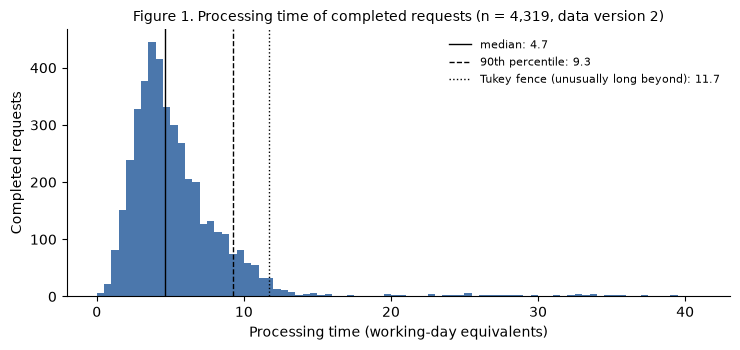

In [5]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.hist(completed["processing_days"], bins=np.arange(0, completed["processing_days"].max() + 0.5, 0.5),
        color="#2b5f9e", alpha=0.85)
for value, label, style in [(completed["processing_days"].median(), "median", "-"),
                            (completed["processing_days"].quantile(0.9), "90th percentile", "--"),
                            (FENCE, "Tukey fence (unusually long beyond)", ":")]:
    ax.axvline(value, color="black", ls=style, lw=1, label=f"{label}: {value:.1f}")
ax.legend(fontsize=8, frameon=False, loc="upper right")
ax.set_xlabel("Processing time (working-day equivalents)")
ax.set_ylabel("Completed requests")
ax.set_title(f"Figure 1. Processing time of completed requests (n = {len(completed):,}, data version 2)", fontsize=10)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "processing_time_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

**Figure 1 caption.** *What it shows:* how long completed requests took from submission to team completion, in working-day equivalents, with the median, 90th percentile and Tukey fence marked. *Why it matters:* the shape shows a typical completed request's duration and how long the slow tail is, which is the basis for spotting where delays appear. *What it can't establish:* why some requests took longer, whether the tail reflects capacity or anything else, or how unfinished requests would have ended; it covers completed requests only and describes generated data.

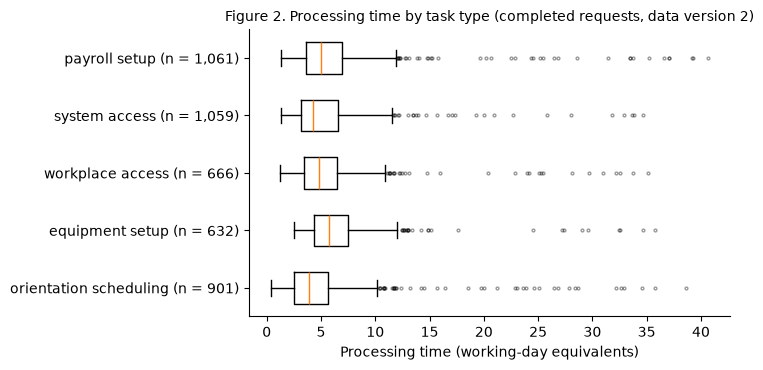

In [6]:
fig, ax = plt.subplots(figsize=(7.5, 3.8))
data_by_task = [completed.loc[completed["task_type"] == t, "processing_days"] for t in TASK_ORDER]
ax.boxplot(data_by_task, orientation="horizontal", whis=1.5, widths=0.55, flierprops={"markersize": 2, "alpha": 0.4})
ax.set_yticks(range(1, len(TASK_ORDER) + 1),
              [f"{t.replace('_', ' ')} (n = {len(d):,})" for t, d in zip(TASK_ORDER, data_by_task)])
ax.invert_yaxis()                                                    # task types top to bottom in table order
ax.set_xlabel("Processing time (working-day equivalents)")
ax.set_title("Figure 2. Processing time by task type (completed requests, data version 2)", fontsize=10)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "processing_time_by_task_type.png", dpi=150, bbox_inches="tight")
plt.show()

**Figure 2 caption.** *What it shows:* the spread of processing time for completed requests by task type, with sample sizes shown. Each box covers the middle 50%, and the line inside marks the median. Whiskers extend to the most extreme values within 1.5 × IQR of each group's own quartiles; points beyond them are shown separately and are not necessarily errors or operational failures. These group-specific limits differ from the overall "unusually long" threshold used in the summary table.

*Why it matters:* it shows which task types tend to take longer and have longer tails, suggesting where monitoring could focus.

*What it can't establish:* the uncertainty around these differences (notebook 03 adds employee-level confidence intervals) or what causes them. Task types differ in their generated processing ranges, workload and timing, and unfinished requests are excluded.